# Análisis exploratorio y limpieza de datos
**Proyecto:** Agente de optimización de rutas y logística de entregas (Grupo 3)
**Dataset:** `parcel_demand_scenario_1.csv`

## Para qué sirve este análisis
El agente va a decidir qué paquetes van en qué vehículo y en qué orden se entregan. Esas decisiones dependen de
las coordenadas, el peso, el volumen y los horarios. Si alguno de esos datos está mal, el agente decide mal.
Por eso, antes de construirlo, respondemos cuatro preguntas:
1. ¿Los datos están completos y son coherentes?
2. ¿Qué forma tienen (rangos, distribuciones, valores raros)?
3. ¿Qué características del problema se desprenden de ellos (depósitos, ventanas, zonas)?
4. ¿Qué columnas nuevas hay que calcular para que el agente pueda trabajar?

Cada sección explica **qué se hace, por qué y qué se decide**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 30)

candidatos = [Path("../backend/data/raw/parcel_demand_scenario_1.csv"),
              Path("backend/data/raw/parcel_demand_scenario_1.csv"),
              Path("parcel_demand_scenario_1.csv")]
RUTA = next(p for p in candidatos if p.exists())
IMG = Path("../docs/img") if Path("../docs").exists() else Path("img")
SALIDA = Path("../backend/data/processed") if Path("../backend").exists() else Path("processed")
IMG.mkdir(parents=True, exist_ok=True); SALIDA.mkdir(parents=True, exist_ok=True)

crudo = pd.read_csv(RUTA)
print("Archivo:", RUTA)
print((crudo.head()).to_string())

Archivo: ../backend/data/raw/parcel_demand_scenario_1.csv
   Latitute_pick_up  Longitude_pick_up  Latitude_delivery  Longitude_delivery pickup_Start pickup_End delivery_Start delivery_End    Weight    Volume
0         40.408519          -3.693242          40.413158           -3.703614     07:00:00   20:00:00       09:00:00     21:00:00  3.203352  0.002060
1         40.408519          -3.693242          40.428425           -3.710197     07:00:00   20:00:00       09:00:00     21:00:00  0.211478  0.016186
2         40.443885          -3.665653          40.410207           -3.707948     07:00:00   20:00:00       09:00:00     21:00:00  1.083183  0.008955
3         40.408519          -3.693242          40.416926           -3.705581     07:00:00   20:00:00       09:00:00     21:00:00  0.179555  0.001050
4         40.443885          -3.665653          40.425653           -3.694551     07:00:00   12:00:00       09:00:00     13:00:00  0.428327  0.008192


## 1. Vistazo general
**Qué hacemos:** ver tamaño, tipos de dato y primeras filas.
**Por qué:** el enunciado exige un mínimo de 5.000 registros, y los tipos de dato indican qué columnas habrá que convertir.

In [2]:
print("Filas y columnas:", crudo.shape)
print()
print(crudo.dtypes)

Filas y columnas: (10984, 10)

Latitute_pick_up      float64
Longitude_pick_up     float64
Latitude_delivery     float64
Longitude_delivery    float64
pickup_Start           object
pickup_End             object
delivery_Start         object
delivery_End           object
Weight                float64
Volume                float64
dtype: object


**Lectura:** el dataset tiene más del doble de los registros mínimos exigidos. Las coordenadas, el peso y el volumen son
numéricos. Los cuatro horarios están guardados como **texto** (`object`), así que no se pueden restar ni comparar
hasta convertirlos.

## 2. Calidad de los datos
**Qué hacemos:** contar valores vacíos, filas repetidas y valores distintos por columna.
**Por qué:** un valor vacío en una coordenada impide calcular una distancia, y una fila repetida contaría un
paquete dos veces (el agente le asignaría doble carga).

In [3]:
calidad = pd.DataFrame({
    "nulos": crudo.isna().sum(),
    "valores_distintos": crudo.nunique(),
})
print("Filas duplicadas:", crudo.duplicated().sum())
print((calidad).to_string())

Filas duplicadas: 0
                    nulos  valores_distintos
Latitute_pick_up        0                  3
Longitude_pick_up       0                  3
Latitude_delivery       0              10984
Longitude_delivery      0              10984
pickup_Start            0                  1
pickup_End              0                  6
delivery_Start          0                  6
delivery_End            0                  6
Weight                  0              10984
Volume                  0              10984


**Lectura y decisión:**
- No hay nulos ni filas duplicadas, por lo que **no hay nada que eliminar ni imputar**. No se inventan errores para tener algo que corregir.
- Los horarios tienen muy pocos valores distintos (se repiten las mismas ventanas), lo que anticipa que casi todos los envíos comparten horarios.
- Las coordenadas de retiro tienen solo 3 combinaciones distintas, y las de entrega son casi todas únicas.

## 3. Normalización de nombres y tipos
**Qué hacemos:** pasar los nombres de columnas a español, sin errores, y convertir los horarios a minutos desde las 00:00.
**Por qué:** el encabezado original `Latitute_pick_up` tiene un error de tipeo, y los nombres mezclan mayúsculas y minúsculas.
Unificarlos evita errores de código. Los horarios en minutos permiten restar y comparar (por ejemplo, saber cuánto dura una ventana).

In [4]:
COLUMNAS = {
    "latitute_pick_up": "lat_origen", "longitude_pick_up": "lon_origen",
    "latitude_delivery": "lat_destino", "longitude_delivery": "lon_destino",
    "pickup_start": "retiro_inicio", "pickup_end": "retiro_fin",
    "delivery_start": "entrega_inicio", "delivery_end": "entrega_fin",
    "weight": "peso", "volume": "volumen",
}
df = crudo.copy()
df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns=COLUMNAS)

for c in ["retiro_inicio", "retiro_fin", "entrega_inicio", "entrega_fin"]:
    df[c + "_min"] = pd.to_timedelta(df[c]).dt.total_seconds() / 60

print((df[["lat_origen", "peso", "volumen", "entrega_inicio", "entrega_inicio_min"]].head(3)).to_string())

   lat_origen      peso   volumen entrega_inicio  entrega_inicio_min
0   40.408519  3.203352  0.002060       09:00:00               540.0
1   40.408519  0.211478  0.016186       09:00:00               540.0
2   40.443885  1.083183  0.008955       09:00:00               540.0


## 4. Validaciones de coherencia
**Qué hacemos:** comprobar reglas que cualquier dato real tiene que cumplir.
**Por qué:** una coordenada fuera de rango, un peso negativo o una ventana que termina antes de empezar son datos imposibles.
Si el agente los usa, produce rutas absurdas.

In [5]:
reglas = pd.DataFrame({
    "regla": [
        "Latitud entre -90 y 90",
        "Longitud entre -180 y 180",
        "Peso mayor que cero",
        "Volumen mayor que cero",
        "La ventana de retiro termina después de empezar",
        "La ventana de entrega termina después de empezar",
    ],
    "filas_que_incumplen": [
        int((~df["lat_origen"].between(-90, 90) | ~df["lat_destino"].between(-90, 90)).sum()),
        int((~df["lon_origen"].between(-180, 180) | ~df["lon_destino"].between(-180, 180)).sum()),
        int((df["peso"] <= 0).sum()),
        int((df["volumen"] <= 0).sum()),
        int((df["retiro_fin_min"] <= df["retiro_inicio_min"]).sum()),
        int((df["entrega_fin_min"] <= df["entrega_inicio_min"]).sum()),
    ],
})
print((reglas).to_string())

                                              regla  filas_que_incumplen
0                            Latitud entre -90 y 90                    0
1                         Longitud entre -180 y 180                    0
2                               Peso mayor que cero                    0
3                            Volumen mayor que cero                    0
4   La ventana de retiro termina después de empezar                    0
5  La ventana de entrega termina después de empezar                    0


In [6]:
# Regla interna detectada: ¿cómo se relacionan la ventana de retiro y la de entrega?
dif_inicio = ((df["entrega_inicio_min"] - df["retiro_inicio_min"]) / 60).value_counts().sort_index()
dif_fin = ((df["entrega_fin_min"] - df["retiro_fin_min"]) / 60).value_counts().sort_index()
print("Horas entre inicio de retiro e inicio de entrega:\n", dif_inicio.to_dict())
print("Horas entre fin de retiro y fin de entrega:\n", dif_fin.to_dict())

Horas entre inicio de retiro e inicio de entrega:
 {2.0: 10434, 3.0: 158, 6.0: 147, 8.0: 96, 9.0: 5, 10.0: 144}
Horas entre fin de retiro y fin de entrega:
 {1.0: 10984}


**Lectura y decisión:**
- Ninguna fila incumple las reglas, así que **no se descarta ningún registro**.
- Hallazgo adicional: en **todas** las filas la entrega termina exactamente 1 hora después de que termina el retiro. Eso indica que el
dataset fue generado con una regla fija, no recogido de entregas reales. Hay que decirlo en la exposición al explicar el origen de los datos.
- La hora de inicio de la entrega sí varía, y es lo que diferencia a los envíos urgentes de los flexibles (sección 7).

## 5. Peso y volumen
**Qué hacemos:** estudiar cómo se distribuyen, buscar valores extremos y ver si están relacionados.
**Por qué:** el agente tiene que respetar la capacidad de cada vehículo. Para eso necesitamos saber cuánto pesan y ocupan los paquetes típicos y si existen casos extremos.

           count    mean     std  min      1%     25%     50%     75%     99%  \
peso     10984.0  1.9585  1.7935  0.1  0.1245  0.7739  1.5608  2.4915  9.1954   
volumen  10984.0  0.0100  0.0071  0.0  0.0003  0.0044  0.0083  0.0148  0.0290   

            max  asimetria  
peso     9.9938     2.1986  
volumen  0.0300     0.8240  

Valores sobre el límite IQR (peso): (728, 5.068)
Valores sobre el límite IQR (volumen): (0, 0.03)
Envíos con volumen menor a 0,0001: 31
Correlación peso-volumen: 0.259


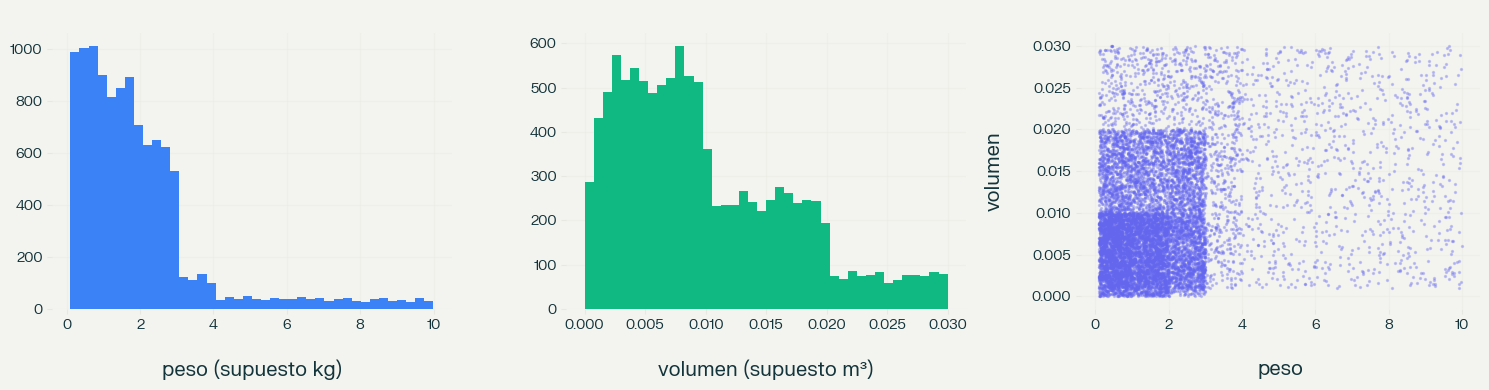

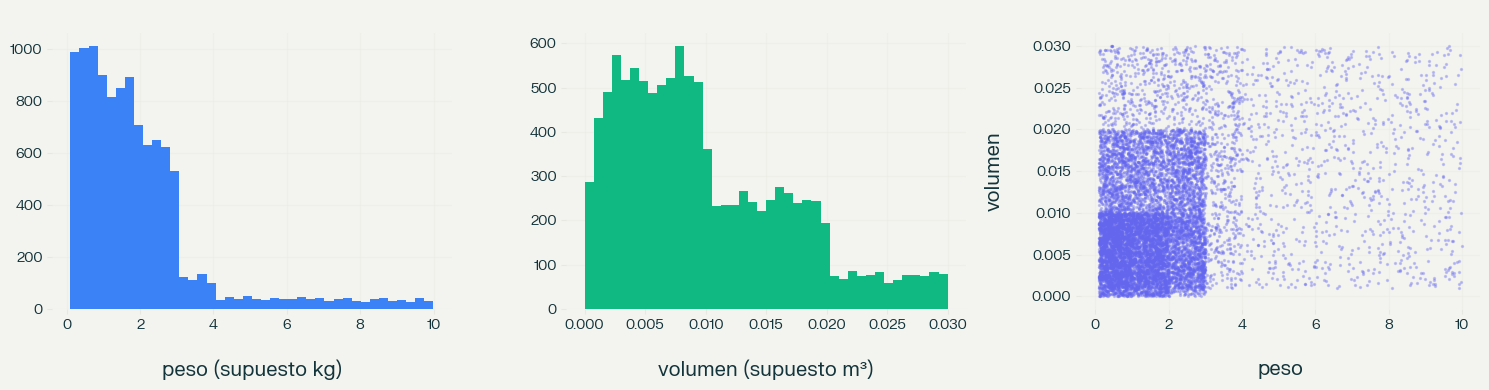

In [7]:
resumen = df[["peso", "volumen"]].describe(percentiles=[.01, .25, .5, .75, .99]).T
resumen["asimetria"] = df[["peso", "volumen"]].skew()
print(resumen.round(4))

def fuera_iqr(s):
    q1, q3 = s.quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
    return int((s > lim).sum()), round(lim, 3)
print("\nValores sobre el límite IQR (peso):", fuera_iqr(df["peso"]))
print("Valores sobre el límite IQR (volumen):", fuera_iqr(df["volumen"]))
print("Envíos con volumen menor a 0,0001:", int((df["volumen"] < 1e-4).sum()))
print("Correlación peso-volumen:", round(df["peso"].corr(df["volumen"]), 3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["peso"], bins=40, color="#3b82f6"); ax[0].set_title("Distribución del peso"); ax[0].set_xlabel("peso (supuesto kg)")
ax[1].hist(df["volumen"], bins=40, color="#10b981"); ax[1].set_title("Distribución del volumen"); ax[1].set_xlabel("volumen (supuesto m³)")
ax[2].scatter(df["peso"], df["volumen"], s=2, alpha=.3, color="#6366f1"); ax[2].set_title("Peso contra volumen")
ax[2].set_xlabel("peso"); ax[2].set_ylabel("volumen")
plt.tight_layout(); plt.savefig(IMG / "01_peso_volumen.png", bbox_inches="tight"); plt.show()

**Lectura y decisión:**
- El peso va de 0,1 a casi 10 y se concentra en valores bajos (mediana cerca de 1,6): hay muchos paquetes livianos y pocos pesados. Por eso la media (2,0) queda por encima de la mediana.
- Aparecen cientos de pesos por encima del límite estadístico (1,5 veces el rango intercuartil), pero son paquetes de entre 5 y 10: valores **posibles**, no errores. **No se eliminan.** Quitarlos distorsionaría la carga real que el agente debe repartir.
- El volumen es muy pequeño (hasta 0,03) y 31 envíos tienen volúmenes casi nulos. Son raros, pero positivos y coherentes con un paquete diminuto. Se conservan y quedan documentados.
- Peso y volumen casi no se relacionan (correlación baja). Esto importa: un vehículo se puede llenar **por peso o por volumen**, y el agente tiene que controlar las dos capacidades por separado.
- **Unidades:** el archivo no las indica. Se asumen kg y m³ porque los rangos son razonables para paquetes con esas unidades. Es un supuesto a confirmar con la fuente.

## 6. Ubicaciones y depósitos
**Qué hacemos:** identificar cuántos puntos de retiro existen y dibujar dónde están las entregas.
**Por qué:** el agente agrupa entregas por cercanía y parte de un depósito. Necesitamos saber desde dónde sale cada paquete y cómo se distribuye el territorio.

                lat    lon  envios  peso_total  porcentaje_envios
id_deposito                                                      
D1           40.444 -3.666    5814   11433.825               52.9
D2           40.409 -3.693    4574    8920.070               41.6
D3           40.472 -3.677     596    1158.814                5.4


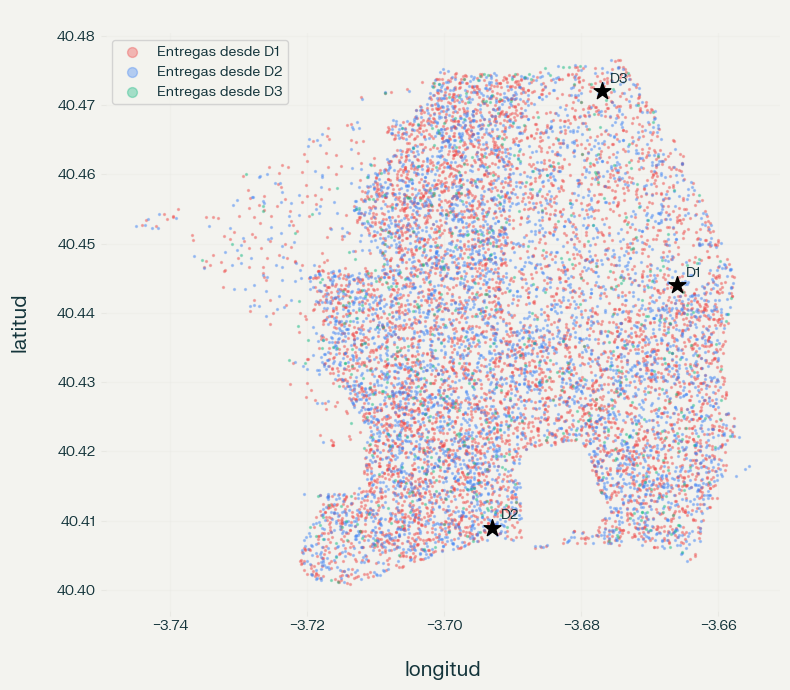

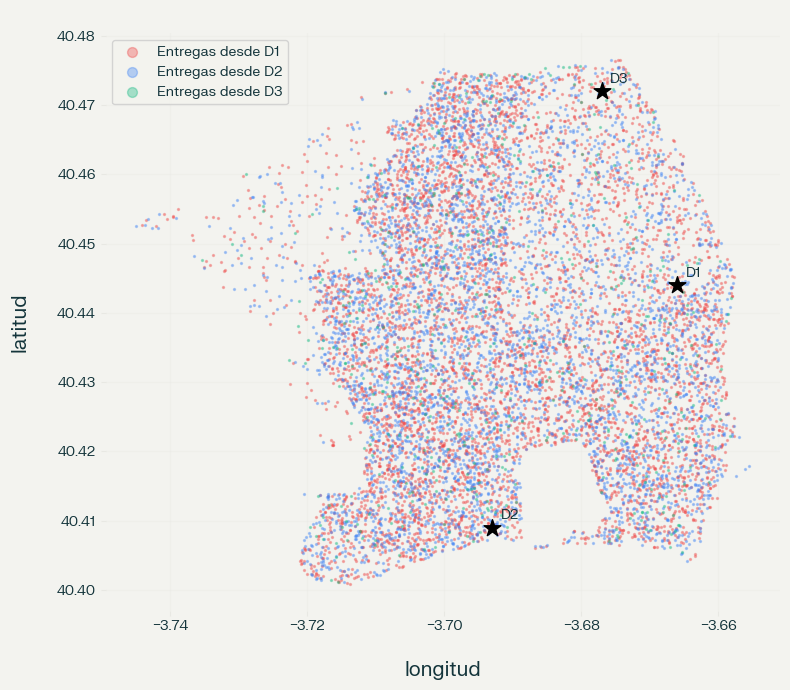

In [8]:
orden = (df.groupby(["lat_origen", "lon_origen"]).size().sort_values(ascending=False).index)
mapa_dep = {k: f"D{i + 1}" for i, k in enumerate(orden)}
df["id_deposito"] = [mapa_dep[(a, b)] for a, b in zip(df["lat_origen"], df["lon_origen"])]

deps = df.groupby("id_deposito").agg(
    lat=("lat_origen", "first"), lon=("lon_origen", "first"),
    envios=("peso", "size"), peso_total=("peso", "sum")).round(3)
deps["porcentaje_envios"] = (deps["envios"] / len(df) * 100).round(1)
print(deps)

colores = {"D1": "#ef4444", "D2": "#3b82f6", "D3": "#10b981"}
fig, ax = plt.subplots(figsize=(8, 7))
for d, g in df.groupby("id_deposito"):
    ax.scatter(g["lon_destino"], g["lat_destino"], s=2, alpha=.35, color=colores[d], label=f"Entregas desde {d}")
for d, r in deps.iterrows():
    ax.scatter(r["lon"], r["lat"], s=160, marker="*", color="black", zorder=5)
    ax.annotate(d, (r["lon"], r["lat"]), textcoords="offset points", xytext=(6, 6), fontweight="bold")
ax.set_title("Entregas por depósito de origen"); ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.legend(markerscale=5); plt.savefig(IMG / "02_mapa_depositos.png", bbox_inches="tight"); plt.show()

**Lectura y decisión:**
- Hay **3 puntos de retiro**, que se tratan como los depósitos D1, D2 y D3. D1 concentra algo más de la mitad de los envíos y D3 muy pocos.
- Las entregas de los tres depósitos **se mezclan en el mismo territorio**: el centro de las entregas de cada depósito difiere en menos de 0,001 grados (unos 100 metros) y la dispersión es la misma, es decir, cualquier depósito reparte a toda la zona. Esto significa que la asignación de paquetes a depósitos no está dada por la geografía, y el agente tendrá que trabajar con el depósito de origen que cada paquete ya trae.
- Los destinos son casi todos distintos, así que no hay entregas repetidas en la misma dirección que se puedan juntar sin más.

## 7. Distancias
**Qué hacemos:** calcular la distancia en línea recta entre el retiro y la entrega de cada paquete (fórmula de Haversine).
**Por qué:** el objetivo del agente es minimizar kilómetros. Necesitamos saber qué distancias son típicas y cuáles extremas.
**Limitación:** la línea recta es menor que el recorrido real por calles. Sirve para comparar y ordenar, pero subestima los kilómetros reales.

              count  mean   std   min   25%   50%   75%   max
id_deposito                                                  
D1           5814.0  3.18  1.27  0.04  2.34  3.29  4.04  6.71
D2           4574.0  3.59  1.80  0.06  2.13  3.39  4.97  7.71
D3            596.0  4.34  1.90  0.15  2.89  4.53  5.67  8.51


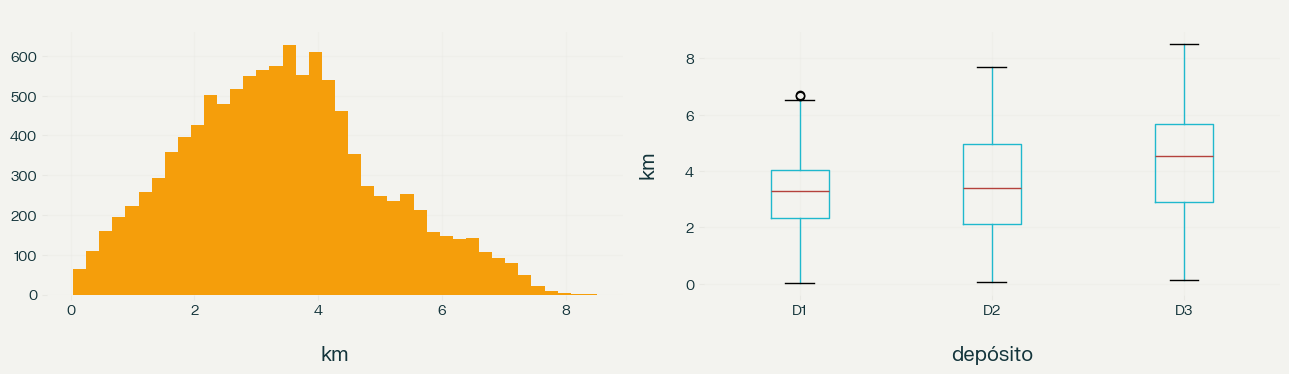

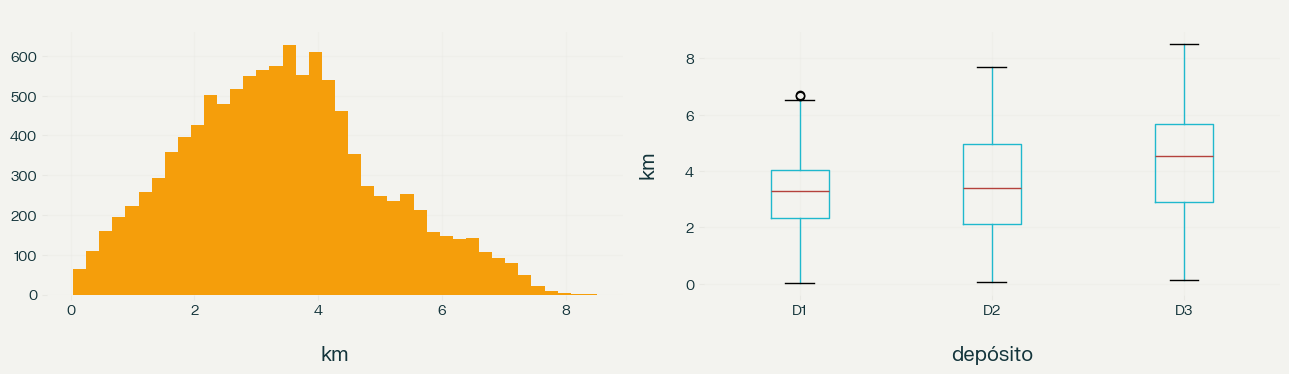

In [9]:
def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2
         + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

df["distancia_km"] = haversine_km(df["lat_origen"], df["lon_origen"], df["lat_destino"], df["lon_destino"]).round(3)
print(df.groupby("id_deposito")["distancia_km"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df["distancia_km"], bins=40, color="#f59e0b"); ax[0].set_title("Distancia retiro-entrega"); ax[0].set_xlabel("km")
df.boxplot(column="distancia_km", by="id_deposito", ax=ax[1]); ax[1].set_title("Distancia por depósito")
ax[1].set_xlabel("depósito"); ax[1].set_ylabel("km"); plt.suptitle("")
plt.tight_layout(); plt.savefig(IMG / "03_distancias.png", bbox_inches="tight"); plt.show()

**Lectura y decisión:**
- Las distancias van de unos 40 metros a unos 8,5 km, con una media cercana a 3,4 km: es un problema **urbano de distancias cortas**.
- D3 (el más alejado del resto) tiene distancias algo mayores. D1 y D2 son similares.
- Como las distancias son cortas, el tiempo de cada parada (bajar, entregar, volver al vehículo) puede pesar tanto como el viaje. Por eso el agente necesitará un **tiempo de servicio por parada**, que el dataset no trae y habrá que suponer.

## 8. Ventanas horarias y urgencia
**Qué hacemos:** medir cuánto dura la ventana de entrega de cada paquete y clasificarlos por urgencia.
**Por qué:** el enunciado pide priorizar por urgencia y respetar los horarios límite. Una ventana de 12 horas es flexible; una de 2 horas obliga a entregar a tiempo.

{2.0: 2, 3.0: 5, 4.0: 507, 5.0: 1, 6.0: 273, 9.0: 158, 10.0: 1, 12.0: 10037}

{'alta': 514, 'media': 432, 'baja': 10038}

urgencia      alta   baja  media
id_deposito                     
D1           0.047  0.913  0.040
D2           0.047  0.915  0.039
D3           0.049  0.914  0.037


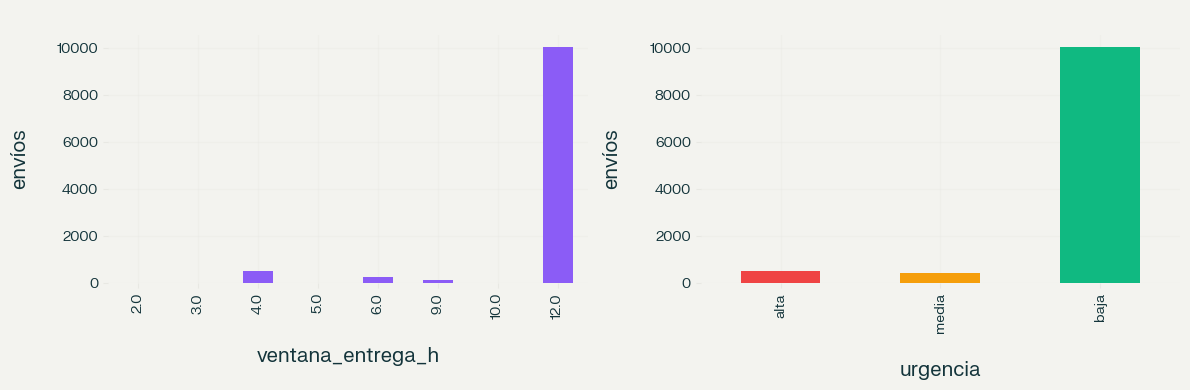

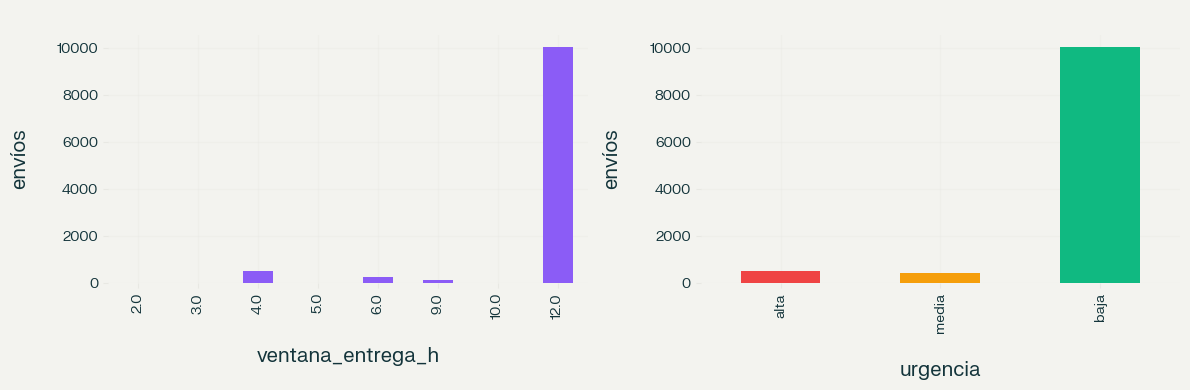

In [10]:
df["ventana_entrega_h"] = ((df["entrega_fin_min"] - df["entrega_inicio_min"]) / 60).round(2)
df["urgencia"] = np.select([df["ventana_entrega_h"] <= 4, df["ventana_entrega_h"] <= 9],
                           ["alta", "media"], default="baja")

vent = df["ventana_entrega_h"].value_counts().sort_index()
urg = df["urgencia"].value_counts().reindex(["alta", "media", "baja"])
print(vent.to_dict()); print(); print(urg.to_dict())
print()
print(pd.crosstab(df["id_deposito"], df["urgencia"], normalize="index").round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
vent.plot.bar(ax=ax[0], color="#8b5cf6"); ax[0].set_title("Duración de la ventana de entrega (horas)"); ax[0].set_ylabel("envíos")
urg.plot.bar(ax=ax[1], color=["#ef4444", "#f59e0b", "#10b981"]); ax[1].set_title("Envíos por urgencia"); ax[1].set_ylabel("envíos")
plt.tight_layout(); plt.savefig(IMG / "04_ventanas_urgencia.png", bbox_inches="tight"); plt.show()

**Lectura y decisión:**
- El **91 %** de los envíos tiene una ventana de 12 horas (de 09:00 a 21:00). Solo cerca del 9 % tiene ventanas más cortas.
- Se definió la urgencia con una regla propia: **alta** si la ventana dura 4 horas o menos, **media** hasta 9 horas, **baja** si dura más. Se eligieron esos cortes porque separan los grupos que aparecen en los datos (2 a 4 horas, 5 a 9 horas y 10 a 12 horas). Es una decisión del grupo y tiene que justificarse en la exposición.
- Consecuencia para el agente: casi todo es flexible, así que para probar bien la tasa de entregas a tiempo hay que fijarse en el pequeño grupo urgente, que es donde el agente puede fallar.
- La proporción de urgencias es parecida entre depósitos, así que la urgencia no depende del depósito de origen.

## 9. Zonas y densidad de entregas
**Qué hacemos:** dividir el mapa en celdas de 0,01 grados (cerca de 1 km) y contar cuántas entregas caen en cada una.
**Por qué:** la consigna pide calcular densidades por zona, y una celda con muchas entregas es candidata a formar un grupo para un mismo vehículo.

Zonas distintas: 60
count     60.0
mean     183.1
std      134.1
min        1.0
25%       59.5
50%      177.5
75%      289.0
max      421.0
Name: entregas, dtype: float64
               entregas  peso_total    lat   lon
zona_id                                         
Z_40.42_-3.7        421     845.538  40.42 -3.70
Z_40.45_-3.7        391     718.490  40.45 -3.70
Z_40.46_-3.7        391     797.598  40.46 -3.70
Z_40.43_-3.71       385     745.664  40.43 -3.71
Z_40.41_-3.7        383     801.377  40.41 -3.70


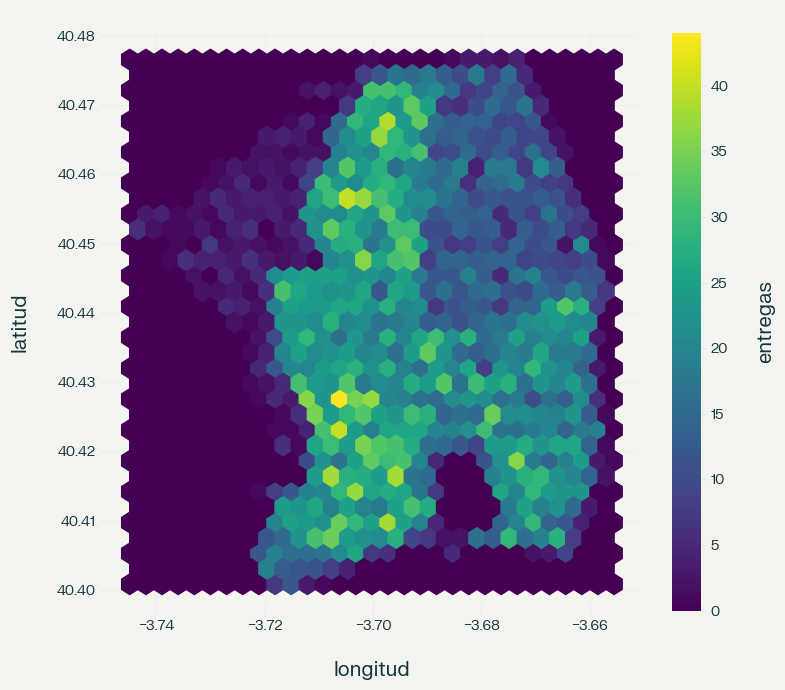

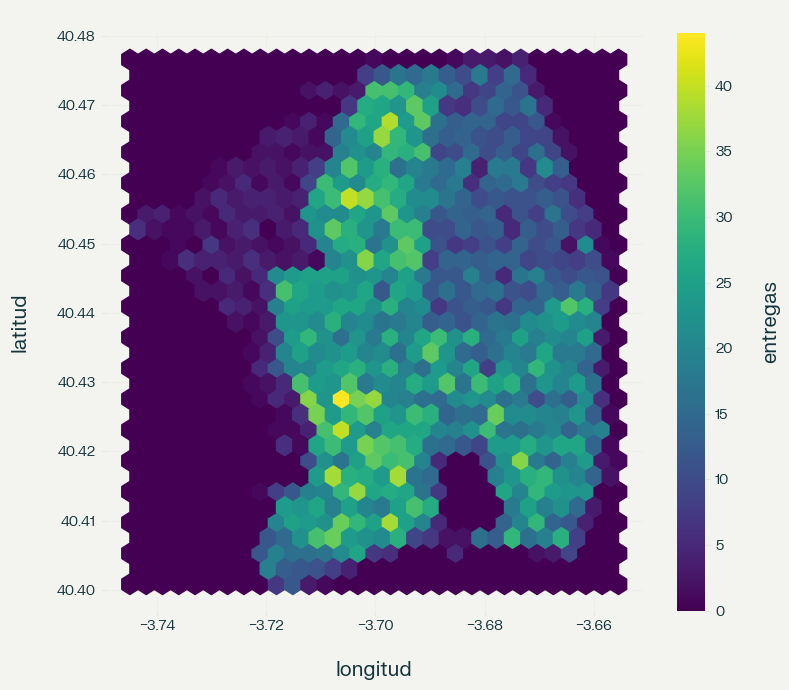

In [11]:
df["zona_id"] = "Z_" + df["lat_destino"].round(2).astype(str) + "_" + df["lon_destino"].round(2).astype(str)
df["densidad_zona"] = df.groupby("zona_id")["peso"].transform("size")

zonas = (df.groupby("zona_id").agg(entregas=("peso", "size"), peso_total=("peso", "sum"),
         lat=("lat_destino", "mean"), lon=("lon_destino", "mean")).round(3)
         .sort_values("entregas", ascending=False))
print("Zonas distintas:", len(zonas))
print(zonas["entregas"].describe().round(1))
print(zonas.head(5))

fig, ax = plt.subplots(figsize=(8, 7))
hb = ax.hexbin(df["lon_destino"], df["lat_destino"], gridsize=30, cmap="viridis")
plt.colorbar(hb, label="entregas"); ax.set_title("Densidad de entregas"); ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
plt.savefig(IMG / "05_densidad.png", bbox_inches="tight"); plt.show()

**Lectura y decisión:**
- Hay unas 60 zonas, desde zonas de borde con 1 a 14 entregas hasta zonas con más de 400 (la mediana es de unas 178 entregas por zona). La demanda no está uniformemente repartida, pero tampoco hay un único foco.
- El tamaño de celda (0,01 grados) es una **simplificación inicial**. En la etapa del agente se puede reemplazar o complementar con un agrupamiento más fino (por ejemplo, k-means), y el resultado se compara con estas zonas.

## 10. Columnas calculadas y dataset final
**Qué hacemos:** agregar las columnas que el agente necesita y guardar el dataset limpio.
**Por qué:** el dataset original no trae identificador, distancia, urgencia, zona ni tiempo de viaje. Todas se **calculan a partir de datos que ya existen**; no se inventa nada.

In [12]:
VELOCIDAD_KMH = 25.0   # SUPUESTO: velocidad urbana promedio, a confirmar en grupo
df.insert(0, "id_envio", ["E" + str(i + 1).zfill(5) for i in range(len(df))])
df["tiempo_viaje_min"] = (df["distancia_km"] / VELOCIDAD_KMH * 60).round(1)
df["origen_dato"] = "original"

df.to_csv(SALIDA / "envios_limpio.csv", index=False)
print("Guardado:", SALIDA / "envios_limpio.csv", "| filas:", len(df), "| columnas:", df.shape[1])

print((pd.DataFrame({
    "columna_nueva": ["id_envio", "id_deposito", "distancia_km", "ventana_entrega_h", "urgencia",
                      "tiempo_viaje_min", "zona_id", "densidad_zona", "origen_dato"],
    "se_calcula_con": ["número de fila", "coordenadas de retiro", "coordenadas (Haversine)", "horarios de entrega",
                       "ancho de la ventana", "distancia y velocidad supuesta", "coordenadas de entrega",
                       "conteo por zona", "marca de trazabilidad (original o generado)"],
})).to_string())

Guardado: ../backend/data/processed/envios_limpio.csv | filas: 10984 | columnas: 23
       columna_nueva                               se_calcula_con
0           id_envio                               número de fila
1        id_deposito                        coordenadas de retiro
2       distancia_km                      coordenadas (Haversine)
3  ventana_entrega_h                          horarios de entrega
4           urgencia                          ancho de la ventana
5   tiempo_viaje_min               distancia y velocidad supuesta
6            zona_id                       coordenadas de entrega
7      densidad_zona                              conteo por zona
8        origen_dato  marca de trazabilidad (original o generado)


## 11. Conclusiones

**Qué encontramos**
- El dataset es utilizable: 10.984 registros, sin nulos, duplicados ni datos imposibles.
- Tiene 3 depósitos que reparten sobre el mismo territorio.
- Las distancias son cortas (media cerca de 3,4 km) y el 91 % de los envíos tiene una ventana de 12 horas.
- Peso y volumen casi no se relacionan, y no se detectaron errores en ninguno.

**Qué decidimos**
- No eliminar ni imputar datos, porque no hay errores que corregir.
- Mantener los valores extremos de peso y volumen por ser posibles.
- Definir la urgencia, la zona y el depósito con reglas propias, documentadas arriba.
- Crear columnas calculadas en lugar de generar datos nuevos.

**Limitaciones y supuestos a declarar**
- Unidades de peso y volumen no indicadas (se asumen kg y m³).
- La entrega termina siempre 1 hora después del fin del retiro: el dataset parece generado con reglas, no tomado de entregas reales.
- La distancia es en línea recta, no por calles.
- La velocidad de 25 km/h es un supuesto.
- Faltan datos de flota y tiempos de parada, que habrá que definir (la flota se propone como tabla aparte).

**Cómo usa esto el agente**
- Asignar paquetes a vehículos controlando **peso y volumen por separado**.
- Priorizar el pequeño grupo de urgencia alta y comprobar que se cumplan sus horarios.
- Agrupar por cercanía usando las zonas como punto de partida.
- Medir los resultados con los KPI del enunciado: kilómetros por ruta y tasa de entregas a tiempo.